<h1 style="background-color: #92D050; color: black; text-align: center; padding: 12px; border-radius: 6px;">Online Shopping Behavior Analysis</h1>


Introduction

This project analyzes online shopping session data to understand customer purchasing behavior and identify patterns associated with completed purchases. The analysis includes data cleaning, exploratory data analysis, and examination of purchase trends across different months and visitor types.

Data Source

The dataset used in this project is the Online Shoppers Purchasing Intention Dataset, obtained from the UCI Machine Learning Repository.

The dataset contains information about online shopping sessions, including page visits, browsing duration, visitor type, and whether a purchase was completed.

Dataset Source: https://archive.ics.uci.edu/dataset/468/online+shoppers+purchasing+intention+dataset

<h1 style="background-color: #92D050; color: black; text-align: center; padding: 12px; border-radius: 6px;">Data Loading and Initial Overview</h1>

This section focuses on loading the dataset and understanding its basic structure before performing data cleaning and exploratory data analysis.

Loading Required Libraries

The Pandas library is used to load and manipulate the dataset and perform data analysis.

Loading the Dataset

The dataset is loaded into a Pandas DataFrame using the read_csv() function. The number of rows and columns and the first five records are displayed to understand the dataset’s initial structure.

In [1]:
import pandas as pd

df = pd.read_csv("online_shoppers_intention.csv")

print("Dataset loaded successfully!")
print("Rows and columns:", df.shape)
print("\nFirst 5 rows:")
display(df.head())

Dataset loaded successfully!
Rows and columns: (12330, 18)

First 5 rows:


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


<h1 style="background-color: #92D050; color: black; text-align: center; padding: 12px; border-radius: 6px;">Data Cleaning</h1>

Data cleaning is performed to improve data quality and prepare the dataset for accurate analysis. The process includes checking missing values, removing duplicate records, checking negative values, and standardizing text values.

Checking Missing Values

This step checks each column for missing values using Pandas. It helps identify incomplete data before performing further analysis.

In [2]:
print("Missing values in each column:")
print(df.isnull().sum())

print("\nTotal missing values:", df.isnull().sum().sum())

Missing values in each column:
Administrative             0
Administrative_Duration    0
Informational              0
Informational_Duration     0
ProductRelated             0
ProductRelated_Duration    0
BounceRates                0
ExitRates                  0
PageValues                 0
SpecialDay                 0
Month                      0
OperatingSystems           0
Browser                    0
Region                     0
TrafficType                0
VisitorType                0
Weekend                    0
Revenue                    0
dtype: int64

Total missing values: 0


Removing Duplicate Rows

Duplicate records can affect the accuracy of data analysis. This step identifies and removes duplicate rows to improve the quality of the dataset.

In [3]:
print("Total duplicate rows:", df.duplicated().sum())

Total duplicate rows: 125


In [4]:
df = df.drop_duplicates()

print("Rows after removing duplicates:", df.shape[0])
print("Remaining duplicate rows:", df.duplicated().sum())

Rows after removing duplicates: 12205
Remaining duplicate rows: 0


Checking Data Types

This step examines the data type of each column to understand the structure of the dataset and ensure that numerical and categorical variables are represented appropriately.

In [5]:
print(df.dtypes)

Administrative               int64
Administrative_Duration    float64
Informational                int64
Informational_Duration     float64
ProductRelated               int64
ProductRelated_Duration    float64
BounceRates                float64
ExitRates                  float64
PageValues                 float64
SpecialDay                 float64
Month                          str
OperatingSystems             int64
Browser                      int64
Region                       int64
TrafficType                  int64
VisitorType                    str
Weekend                       bool
Revenue                       bool
dtype: object


Displaying Summary Statistics

This step uses the describe() function to display summary statistics for numerical columns, including count, mean, standard deviation, minimum, maximum, and quartile values. This helps us understand the distribution and range of the dataset’s numerical features.

In [6]:
print("Minimum and maximum values:")
print(df.describe())

Minimum and maximum values:
       Administrative  Administrative_Duration  Informational  \
count    12205.000000             12205.000000   12205.000000   
mean         2.338878                81.646331       0.508726   
std          3.330436               177.491845       1.275617   
min          0.000000                 0.000000       0.000000   
25%          0.000000                 0.000000       0.000000   
50%          1.000000                 9.000000       0.000000   
75%          4.000000                94.700000       0.000000   
max         27.000000              3398.750000      24.000000   

       Informational_Duration  ProductRelated  ProductRelated_Duration  \
count            12205.000000    12205.000000             12205.000000   
mean                34.825454       32.045637              1206.982457   
std                141.424807       44.593649              1919.601400   
min                  0.000000        0.000000                 0.000000   
25%             

Checking Unique Month Values

In this step, I check the unique values in the Month column to identify inconsistencies in month names before cleaning. This helps ensure that the month labels follow a consistent format throughout the dataset.

In [7]:
print("Unique months:")
print(df["Month"].unique())

Unique months:
<StringArray>
['Feb', 'Mar', 'May', 'Oct', 'June', 'Jul', 'Aug', 'Nov', 'Sep', 'Dec']
Length: 10, dtype: str


Standardizing Month Names

In this step, I standardize the month names in the Month column to ensure consistent formatting. This helps avoid inconsistencies when grouping and analyzing shopping sessions by month.

In [8]:
df["Month"] = df["Month"].replace({
    "June": "Jun",
    "Jul": "Jul",
    "Aug": "Aug",
    "Sep": "Sep",
    "Oct": "Oct",
    "Nov": "Nov",
    "Dec": "Dec"
})

print("Unique months after cleaning:")
print(df["Month"].unique())

Unique months after cleaning:
<StringArray>
['Feb', 'Mar', 'May', 'Oct', 'Jun', 'Jul', 'Aug', 'Nov', 'Sep', 'Dec']
Length: 10, dtype: str


Checking Visitor Types

In this step, I examine the different visitor types in the dataset and count how many records belong to each type. This helps me understand the distribution of visitors, such as returning visitors and new visitors.

In [9]:
print("Visitor types:")
print(df["VisitorType"].value_counts())

Visitor types:
VisitorType
Returning_Visitor    10431
New_Visitor           1693
Other                   81
Name: count, dtype: int64


Analyzing Purchase Outcomes

In this step, I calculate the number and percentage of shopping sessions that resulted in a purchase and those that did not. This helps me understand the conversion rate and the proportion of visitors who leave without purchasing.

In [10]:
print("Revenue distribution:")
print(df["Revenue"].value_counts())

print("\nRevenue percentage:")
print(df["Revenue"].value_counts(normalize=True) * 100)

Revenue distribution:
Revenue
False    10297
True      1908
Name: count, dtype: int64

Revenue percentage:
Revenue
False    84.367063
True     15.632937
Name: proportion, dtype: float64


Checking Unique Values in Important Columns

In this step, I check the unique values in the Weekend, Revenue, and VisitorType columns. This helps verify the available categories and confirm that these columns contain the expected values for further analysis.

In [11]:
print("Unique values in Weekend:")
print(df["Weekend"].unique())

print("\nUnique values in Revenue:")
print(df["Revenue"].unique())

print("\nUnique values in VisitorType:")
print(df["VisitorType"].unique())

Unique values in Weekend:
[False  True]

Unique values in Revenue:
[False  True]

Unique values in VisitorType:
<StringArray>
['Returning_Visitor', 'New_Visitor', 'Other']
Length: 3, dtype: str


Analyzing Shopping Sessions by Month

In this step, I calculate the number of shopping sessions recorded in each month using the Month column. This helps identify the months with the highest and lowest website traffic and understand the distribution of shopping sessions throughout the year.

In [12]:
print("Month values and their counts:")
print(df["Month"].value_counts())

Month values and their counts:
Month
May    3329
Nov    2982
Mar    1860
Dec    1706
Oct     549
Sep     448
Aug     433
Jul     432
Jun     285
Feb     181
Name: count, dtype: int64


Checking for Negative Values

In this step, I select all numerical columns and count the negative values in each column. This helps identify potentially invalid values that may affect the accuracy of the data analysis.

In [13]:
numeric_df = df.select_dtypes(include="number")

print("Negative values in each numerical column:")
print((numeric_df < 0).sum())

Negative values in each numerical column:
Administrative             0
Administrative_Duration    0
Informational              0
Informational_Duration     0
ProductRelated             0
ProductRelated_Duration    0
BounceRates                0
ExitRates                  0
PageValues                 0
SpecialDay                 0
OperatingSystems           0
Browser                    0
Region                     0
TrafficType                0
dtype: int64


Checking for Unnecessary Spaces in Text Columns

In this step, I examine the text columns to identify values containing unnecessary leading or trailing spaces. Removing these spaces helps maintain consistent text values and prevents issues during data grouping and analysis.Checking for Unnecessary Spaces in Text Columns

In this step, I examine the text columns to identify values containing unnecessary leading or trailing spaces. Removing these spaces helps maintain consistent text values and prevents issues during data grouping and analysis.

In [14]:
text_columns = df.select_dtypes(include="object")

print("Unnecessary spaces in each text column:")
print(text_columns.apply(lambda col: col.str.strip().ne(col).sum()))

Unnecessary spaces in each text column:
Month          0
VisitorType    0
dtype: int64


C:\Users\ASUS\AppData\Local\Temp\ipykernel_10800\3155839905.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  text_columns = df.select_dtypes(include="object")


Saving the Cleaned Dataset

In this step, I save the cleaned dataset as online_shoppers_intention_cleaned.csv without including the DataFrame index. I also display a success message and the final dataset shape to confirm that the cleaned data has been saved successfully.

In [15]:
df.to_csv("online_shoppers_intention_cleaned.csv", index=False)

print("Cleaned dataset saved successfully!")
print("Final dataset shape:", df.shape)

Cleaned dataset saved successfully!
Final dataset shape: (12205, 18)


<h1 style="background-color: #92D050; color: black; text-align: center; padding: 12px; border-radius: 6px;">Exploratory Data Analysis (EDA)</h1>

In this section, I explore the cleaned online shopping dataset to understand customer behavior, purchase outcomes, and shopping trends. This analysis helps identify useful patterns and insights from the data.

Reviewing the Cleaned Dataset Structure

In this step, I review the shape of the cleaned dataset, list all column names, and examine their data types. This helps confirm the dataset structure and understand which columns are available for exploratory data analysis.

In [16]:
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

Dataset shape: (12205, 18)

Column names:
['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay', 'Month', 'OperatingSystems', 'Browser', 'Region', 'TrafficType', 'VisitorType', 'Weekend', 'Revenue']

Data types:
Administrative               int64
Administrative_Duration    float64
Informational                int64
Informational_Duration     float64
ProductRelated               int64
ProductRelated_Duration    float64
BounceRates                float64
ExitRates                  float64
PageValues                 float64
SpecialDay                 float64
Month                          str
OperatingSystems             int64
Browser                      int64
Region                       int64
TrafficType                  int64
VisitorType                    str
Weekend                       bool
Revenue                       bool
dtype: object


Descriptive Statistical Analysis

In this step, I use the describe() function to generate summary statistics for the numerical columns. These statistics include the count, mean, standard deviation, minimum, maximum, and quartile values. This helps me understand the distribution and range of the numerical data.

In [17]:
df.describe()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,OperatingSystems,Browser,Region,TrafficType
count,12205.000000,12205.000000,12205.000000,12205.000000,12205.000000,12205.000000,12205.000000,12205.000000,12205.000000,12205.000000,12205.000000,12205.000000,12205.000000,12205.000000
mean,2.338878,81.646331,0.508726,34.825454,32.045637,1206.982457,0.020370,0.041466,5.949574,0.061942,2.124211,2.357804,3.153298,4.073904
std,3.330436,177.491845,1.275617,141.424807,44.593649,1919.601400,0.045255,0.046163,18.653671,0.199666,0.906823,1.710114,2.402340,4.016654
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,1.000000
25%,0.000000,0.000000,0.000000,0.000000,8.000000,193.000000,0.000000,0.014231,0.000000,0.000000,2.000000,2.000000,1.000000,2.000000
50%,1.000000,9.000000,0.000000,0.000000,18.000000,608.942857,0.002899,0.025000,0.000000,0.000000,2.000000,2.000000,3.000000,2.000000
75%,4.000000,94.700000,0.000000,0.000000,38.000000,1477.154762,0.016667,0.048529,0.000000,0.000000,3.000000,2.000000,4.000000,4.000000
max,27.000000,3398.750000,24.000000,2549.375000,705.000000,63973.522230,0.200000,0.200000,361.763742,1.000000,8.000000,13.000000,9.000000,20.000000


Analyzing Purchase Outcomes

In this step, I calculate the number of shopping sessions that resulted in a purchase and those that did not using the Revenue column. I also calculate the percentage of each outcome to understand the website’s purchase conversion rate and identify the proportion of sessions that did not lead to a purchase.

In [18]:
print("Purchase outcomes:")
print(df["Revenue"].value_counts())

print("\nPurchase outcome percentages:")
print((df["Revenue"].value_counts(normalize=True) * 100).round(2))

Purchase outcomes:
Revenue
False    10297
True      1908
Name: count, dtype: int64

Purchase outcome percentages:
Revenue
False    84.37
True     15.63
Name: proportion, dtype: float64


Analyzing Visitor Type Distribution

In this step, I calculate the number and percentage of each visitor type using the VisitorType column. This helps me understand the proportion of returning visitors, new visitors, and other visitor categories on the website.

In [19]:
print("Visitor type counts:")
print(df["VisitorType"].value_counts())

print("\nVisitor type percentages:")
print(
    (df["VisitorType"].value_counts(normalize=True) * 100).round(2)
)

Visitor type counts:
VisitorType
Returning_Visitor    10431
New_Visitor           1693
Other                   81
Name: count, dtype: int64

Visitor type percentages:
VisitorType
Returning_Visitor    85.46
New_Visitor          13.87
Other                 0.66
Name: proportion, dtype: float64


Visitor Type Distribution

In this step, I display the count and percentage of each visitor type to understand the distribution of new, returning, and other visitors in the dataset.

In [20]:
print(df["VisitorType"].value_counts())
print((df["VisitorType"].value_counts(normalize=True) * 100).round(2))


VisitorType
Returning_Visitor    10431
New_Visitor           1693
Other                   81
Name: count, dtype: int64
VisitorType
Returning_Visitor    85.46
New_Visitor          13.87
Other                 0.66
Name: proportion, dtype: float64


Analyzing Monthly Shopping Sessions

In this step, I calculate the number of shopping sessions recorded in each month using the Month column. This helps identify months with higher or lower website traffic and understand seasonal patterns in online shopping activity.

In [21]:
print("Shopping sessions by month:")
print(df["Month"].value_counts())

Shopping sessions by month:
Month
May    3329
Nov    2982
Mar    1860
Dec    1706
Oct     549
Sep     448
Aug     433
Jul     432
Jun     285
Feb     181
Name: count, dtype: int64


Analyzing Weekend and Weekday Sessions

In this step, I count the shopping sessions that occurred on weekends and weekdays using the Weekend column. I also calculate their percentages to understand how website traffic is distributed between weekends and weekdays.

In [22]:
print("Weekend vs weekday sessions:")
print(df["Weekend"].value_counts())

print("\nPercentages:")
print((df["Weekend"].value_counts(normalize=True) * 100).round(2))

Weekend vs weekday sessions:
Weekend
False    9346
True     2859
Name: count, dtype: int64

Percentages:
Weekend
False    76.58
True     23.42
Name: proportion, dtype: float64


Visitor Type vs. Purchase Outcomes

In this step, I use a cross-tabulation to compare visitor types with purchase outcomes using the VisitorType and Revenue columns. This helps me understand how purchase behavior differs between returning visitors, new visitors, and other visitor categories.

In [23]:
print(pd.crosstab(df["VisitorType"], df["Revenue"]))

Revenue            False  True 
VisitorType                    
New_Visitor         1271    422
Other                 65     16
Returning_Visitor   8961   1470


Monthly Shopping Sessions vs. Purchase Outcomes

In this step, I use a cross-tabulation to compare the Month and Revenue columns. This shows the number of sessions that resulted in a purchase and those that did not for each month, helping identify monthly patterns in customer purchasing behavior.

In [24]:
print(pd.crosstab(df["Month"], df["Revenue"]))

Revenue  False  True 
Month                
Aug        357     76
Dec       1490    216
Feb        178      3
Jul        366     66
Jun        256     29
Mar       1668    192
May       2964    365
Nov       2222    760
Oct        434    115
Sep        362     86


<h1 style="background-color: #92D050; color: black; text-align: center; padding: 12px; border-radius: 6px;">Data Visualization</h1>

In this section, I create visualizations to explore online shopping behavior, customer purchase outcomes, and conversion trends. Charts help present patterns in the dataset clearly and make the findings easier to understand.

Purchase Outcome Distribution

This visualization shows the distribution of shopping sessions based on whether a purchase was completed. It helps compare sessions that generated revenue with those that did not.

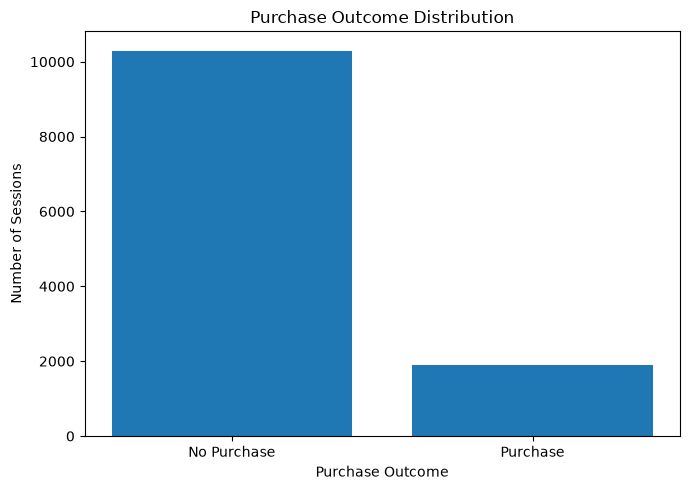

In [25]:
import matplotlib.pyplot as plt

revenue_counts = df["Revenue"].value_counts().reindex([False, True])

plt.figure(figsize=(7, 5))
plt.bar(
    ["No Purchase", "Purchase"],
    revenue_counts.values
)
plt.title("Purchase Outcome Distribution")
plt.xlabel("Purchase Outcome")
plt.ylabel("Number of Sessions")
plt.tight_layout()
plt.show()

Monthly Purchase Outcome Analysis

This visualization compares purchase and non-purchase sessions across different months. It helps identify monthly patterns in customer purchasing behavior and highlights months with higher purchase activity.

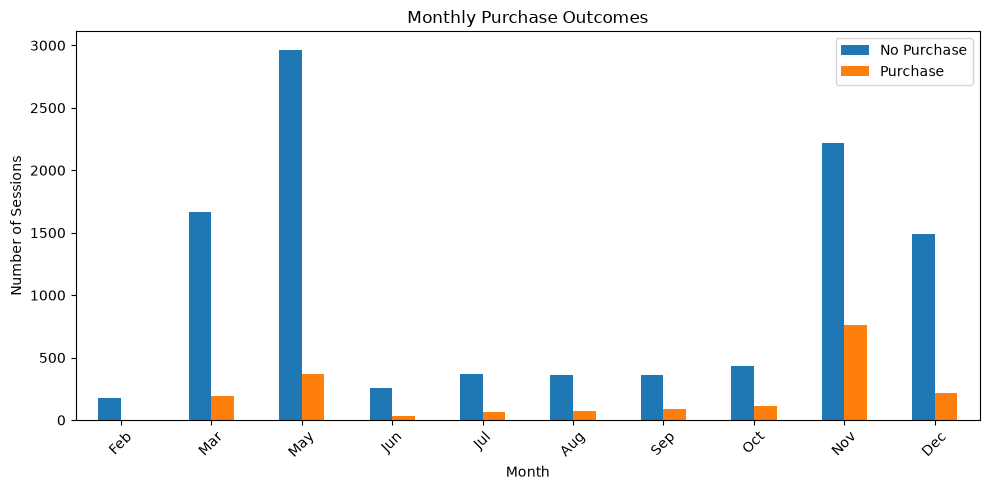

In [27]:
import matplotlib.pyplot as plt
import pandas as pd

monthly_revenue = pd.crosstab(df["Month"], df["Revenue"])
monthly_revenue = monthly_revenue.reindex(
    ["Feb", "Mar", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
).fillna(0)

monthly_revenue.plot(kind="bar", figsize=(10, 5))

plt.title("Monthly Purchase Outcomes")
plt.xlabel("Month")
plt.ylabel("Number of Sessions")
plt.xticks(rotation=45)
plt.legend(["No Purchase", "Purchase"])
plt.tight_layout()
plt.show()

Visitor Type and Purchase Outcomes

This visualization compares purchase and non-purchase sessions across different visitor types. It helps identify differences in purchasing behavior between new visitors, returning visitors, and other visitor categories.

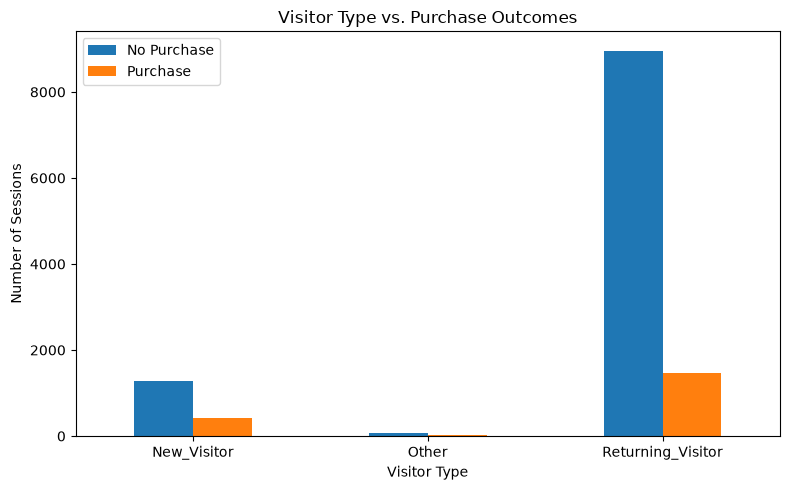

In [28]:
import matplotlib.pyplot as plt
import pandas as pd

visitor_revenue = pd.crosstab(df["VisitorType"], df["Revenue"])
visitor_revenue = visitor_revenue.reindex(
    columns=[False, True], fill_value=0
)

visitor_revenue.plot(kind="bar", figsize=(8, 5))

plt.title("Visitor Type vs. Purchase Outcomes")
plt.xlabel("Visitor Type")
plt.ylabel("Number of Sessions")
plt.xticks(rotation=0)
plt.legend(["No Purchase", "Purchase"])
plt.tight_layout()
plt.show()

Weekend vs. Weekday Shopping Sessions

This visualization compares the number of shopping sessions that occurred on weekends and weekdays. It helps understand how website traffic is distributed across these two periods.

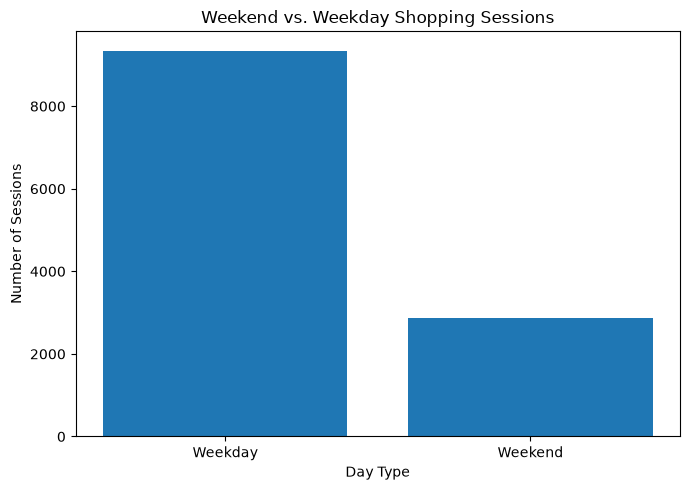

In [29]:
import matplotlib.pyplot as plt

weekend_counts = df["Weekend"].value_counts().reindex([False, True], fill_value=0)

plt.figure(figsize=(7, 5))
plt.bar(
    ["Weekday", "Weekend"],
    weekend_counts.values
)
plt.title("Weekend vs. Weekday Shopping Sessions")
plt.xlabel("Day Type")
plt.ylabel("Number of Sessions")
plt.tight_layout()
plt.show()

Monthly Shopping Session Distribution

This visualization displays the number of shopping sessions recorded in each month. It helps identify months with the highest and lowest website traffic and explore seasonal patterns in online shopping activity.

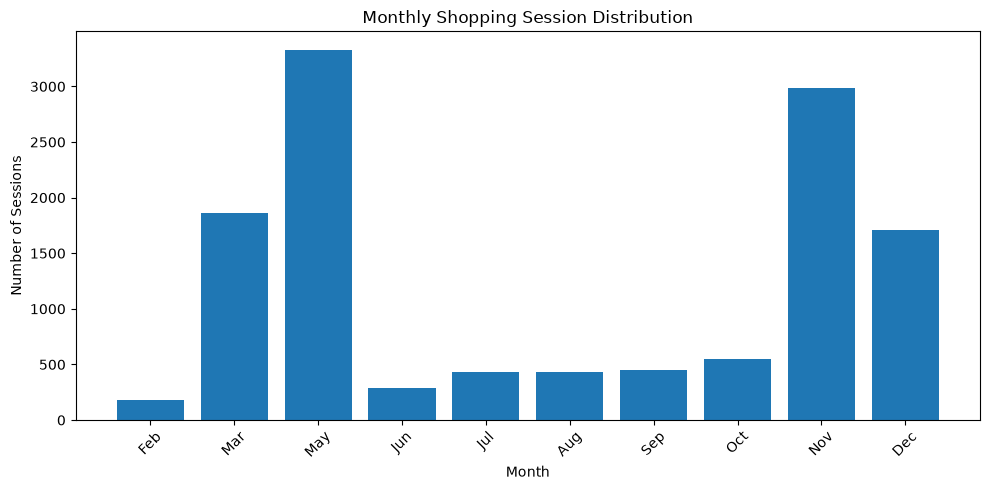

In [30]:
import matplotlib.pyplot as plt

month_counts = df["Month"].value_counts()

month_order = ["Feb", "Mar", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
month_counts = month_counts.reindex(month_order).dropna()

plt.figure(figsize=(10, 5))
plt.bar(month_counts.index, month_counts.values)

plt.title("Monthly Shopping Session Distribution")
plt.xlabel("Month")
plt.ylabel("Number of Sessions")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Monthly Purchase Conversion Rate

This visualization shows the percentage of shopping sessions that resulted in a purchase for each month. It helps compare purchasing performance across months while accounting for differences in the total number of shopping sessions.

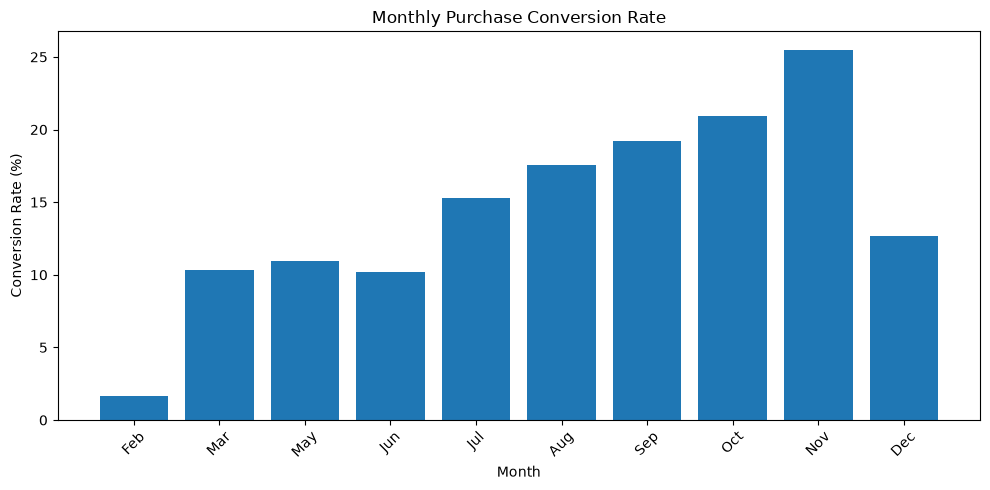

In [31]:
import matplotlib.pyplot as plt
import pandas as pd

monthly_conversion = (
    df.groupby("Month")["Revenue"].mean() * 100
)

month_order = ["Feb", "Mar", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
monthly_conversion = monthly_conversion.reindex(month_order).dropna()

plt.figure(figsize=(10, 5))
plt.bar(monthly_conversion.index, monthly_conversion.values)

plt.title("Monthly Purchase Conversion Rate")
plt.xlabel("Month")
plt.ylabel("Conversion Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Purchase Conversion Rate by Visitor Type

This visualization compares the purchase conversion rate across different visitor types. It helps identify which visitor groups are more likely to complete a purchase and provides insight into customer purchasing behavior.

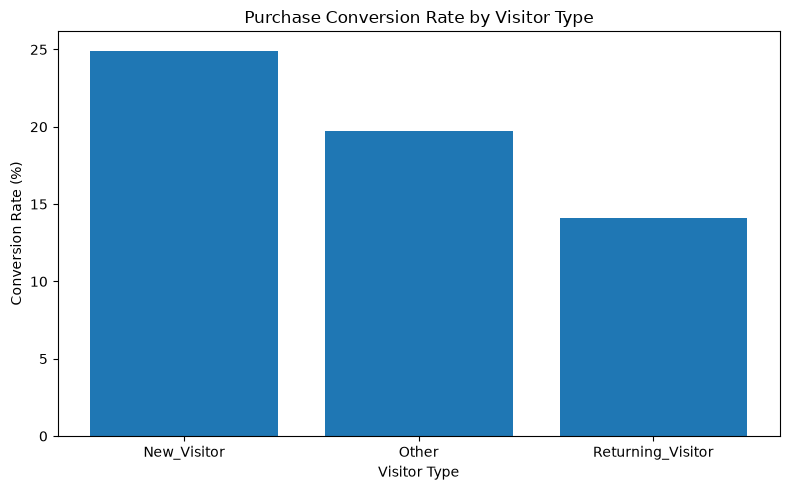

In [32]:
import matplotlib.pyplot as plt

visitor_conversion = df.groupby("VisitorType")["Revenue"].mean() * 100

plt.figure(figsize=(8, 5))
plt.bar(visitor_conversion.index, visitor_conversion.values)

plt.title("Purchase Conversion Rate by Visitor Type")
plt.xlabel("Visitor Type")
plt.ylabel("Conversion Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Average Page Value by Purchase Outcome

This visualization compares the average PageValues for shopping sessions that resulted in a purchase and those that did not. It helps explore the relationship between page value and customer purchase behavior.

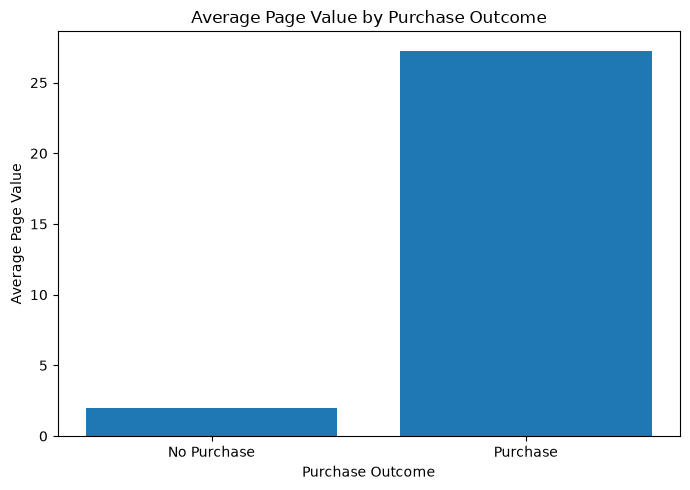

In [33]:
import matplotlib.pyplot as plt

page_value = df.groupby("Revenue")["PageValues"].mean()
page_value = page_value.reindex([False, True])

plt.figure(figsize=(7, 5))
plt.bar(
    ["No Purchase", "Purchase"],
    page_value.values
)

plt.title("Average Page Value by Purchase Outcome")
plt.xlabel("Purchase Outcome")
plt.ylabel("Average Page Value")
plt.tight_layout()
plt.show()

Purchase Distribution Using a Pie Chart

This pie chart shows the percentage distribution of shopping sessions that resulted in a purchase and those that did not. It provides a simple visual representation of the website’s purchase conversion rate.

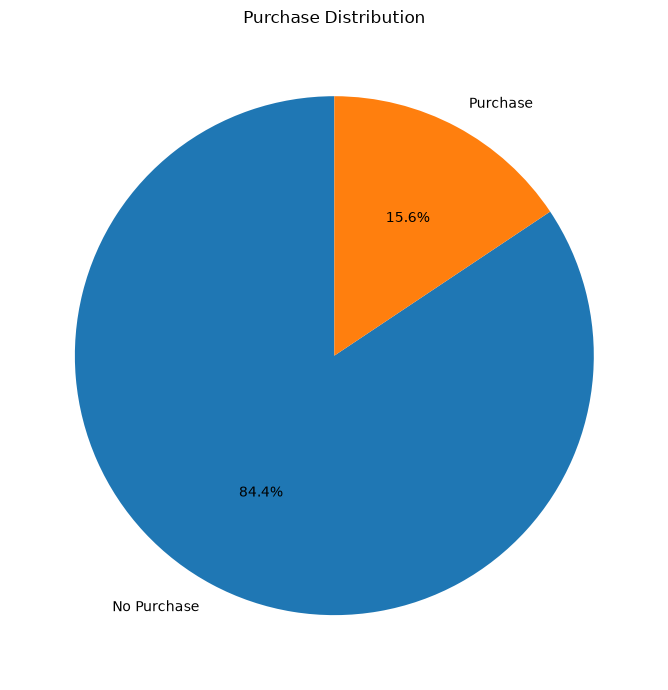

In [34]:
import matplotlib.pyplot as plt

counts = df["Revenue"].value_counts().reindex([False, True], fill_value=0)

plt.figure(figsize=(7, 7))
plt.pie(
    counts.values,
    labels=["No Purchase", "Purchase"],
    autopct="%1.1f%%",
    startangle=90
)
plt.title("Purchase Distribution")
plt.tight_layout()
plt.show()

Monthly Purchase Conversion Trend

This line chart displays the purchase conversion rate across different months. It helps identify changes in purchasing performance throughout the year.

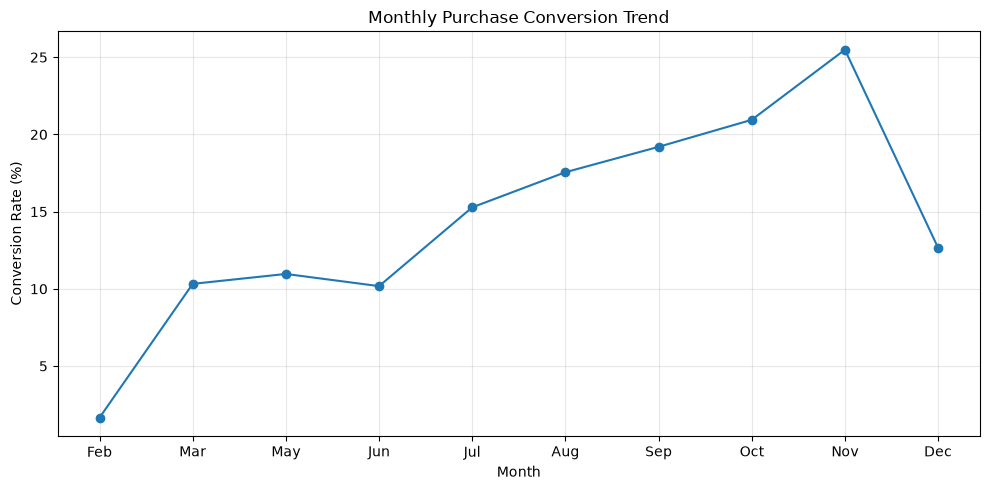

In [35]:
import matplotlib.pyplot as plt

conversion = df.groupby("Month")["Revenue"].mean() * 100
month_order = ["Feb", "Mar", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
conversion = conversion.reindex(month_order).dropna()

plt.figure(figsize=(10, 5))
plt.plot(conversion.index, conversion.values, marker="o")
plt.title("Monthly Purchase Conversion Trend")
plt.xlabel("Month")
plt.ylabel("Conversion Rate (%)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Relationship Between Page Values and Exit Rates

This scatter plot explores the relationship between PageValues and ExitRates. It helps visualize how page values and exit rates vary across shopping sessions.

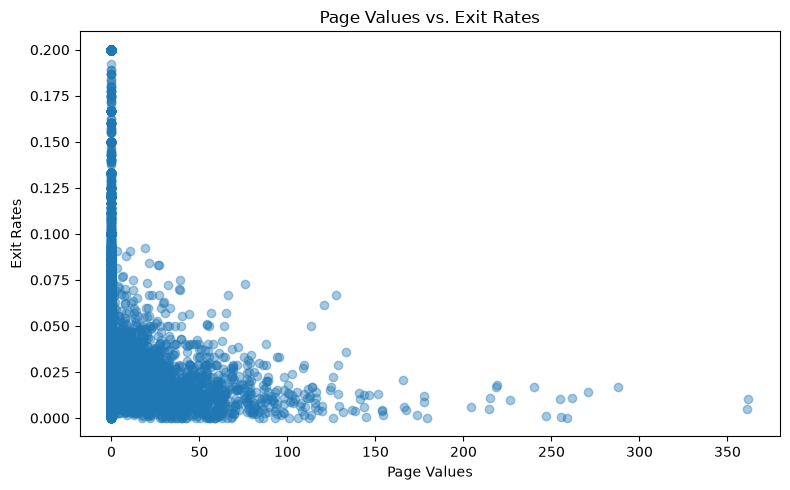

In [36]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.scatter(df["PageValues"], df["ExitRates"], alpha=0.4)
plt.title("Page Values vs. Exit Rates")
plt.xlabel("Page Values")
plt.ylabel("Exit Rates")
plt.tight_layout()
plt.show()

Distribution of Page Values by Purchase Outcome

This box plot compares page values between sessions with and without purchases. It helps examine differences in the distribution, median, and potential outliers of page values.

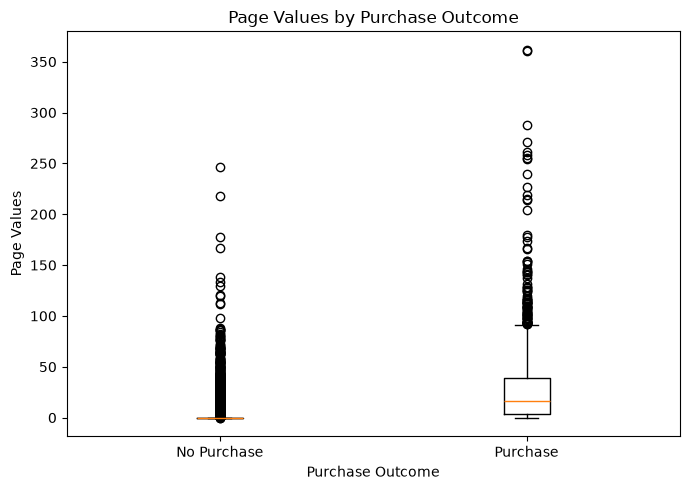

In [37]:
import matplotlib.pyplot as plt

no_purchase = df.loc[df["Revenue"] == False, "PageValues"]
purchase = df.loc[df["Revenue"] == True, "PageValues"]

plt.figure(figsize=(7, 5))
plt.boxplot(
    [no_purchase, purchase],
    tick_labels=["No Purchase", "Purchase"]
)
plt.title("Page Values by Purchase Outcome")
plt.xlabel("Purchase Outcome")
plt.ylabel("Page Values")
plt.tight_layout()
plt.show()

Correlation Heatmap of Numerical Features

This heatmap displays correlations between numerical columns in the dataset. It helps identify variables that have stronger positive or negative linear relationships with one another.

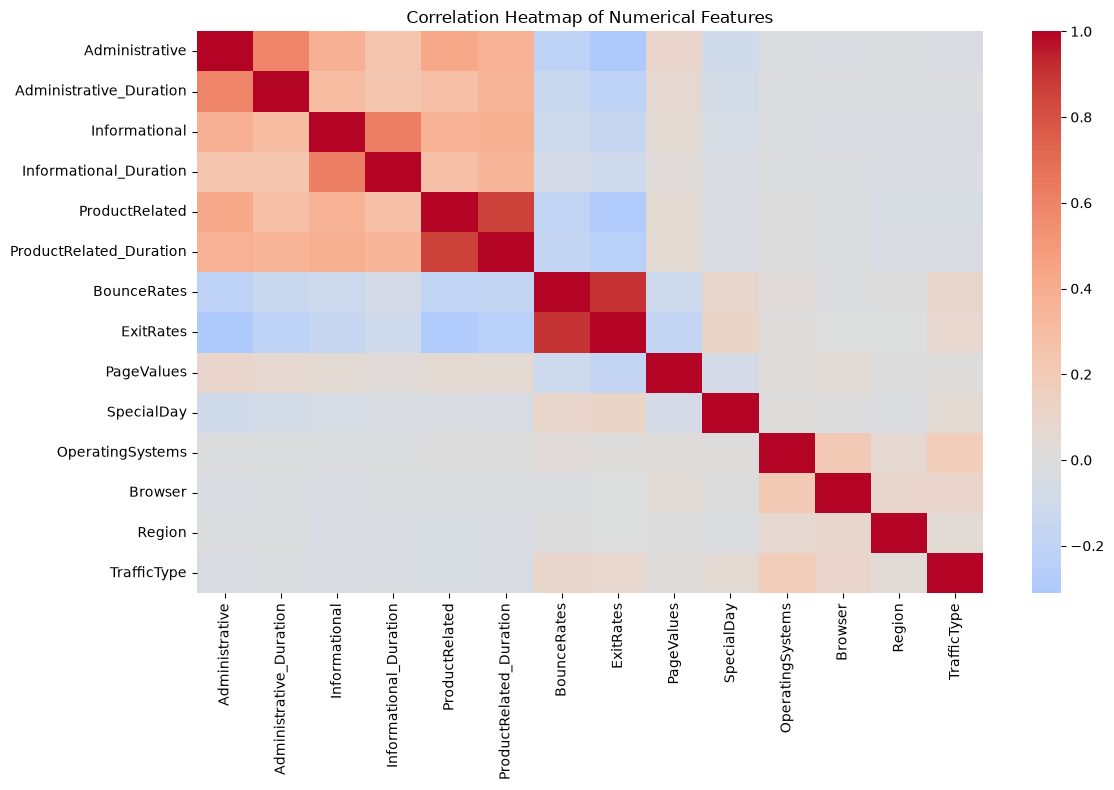

In [38]:
import matplotlib.pyplot as plt
import seaborn as sns

numeric_df = df.select_dtypes(include="number")
correlation = numeric_df.corr()

plt.figure(figsize=(12, 8))
sns.heatmap(correlation, cmap="coolwarm", center=0)
plt.title("Correlation Heatmap of Numerical Features")
plt.tight_layout()
plt.show()

<h1 style="background-color: #92D050; color: black; text-align: center; padding: 12px; border-radius: 6px;">Conclusion</h1>

This project analyzed the Online Shoppers Purchasing Intention dataset to understand customer behavior and purchasing patterns on an e-commerce website.

The data cleaning process removed duplicate records and checked for missing values, inconsistent text formatting, and negative numerical values. Exploratory data analysis examined purchase outcomes, visitor types, monthly shopping sessions, and weekend activity.

The visualizations helped compare purchase and non-purchase sessions, explore monthly conversion rates, and examine the relationship between page values and purchase outcomes.

Overall, this project demonstrates how data cleaning, exploratory data analysis, and visualization can be used to understand online shopping behavior and identify patterns that may help businesses improve their website and customer conversion rates.